# Session 5 — Scaling and data

Session 3 trained one model. This session trains twenty, in five sizes and four training lengths on the same stories, and asks how the loss depends on the number of parameters and the number of tokens. We fit a simple law to the results, use it to ask how to split a fixed compute budget, and then check three things that make scaling results harder to read: repeated data, near-duplicate data, and the choice of metric. It is a longer session (about 90 minutes), because the grid is the point.

**By the end of the session you should be able to:**

1. estimate training compute with $C\approx 6ND$ and read a grid of runs as loss against parameters and against tokens;
2. fit a scaling law to your own runs, say how well it fits, and say where its predictions stop being trustworthy;
3. explain from measurements why repeated data, near-duplicates and a thresholded metric change what a scaling result means.

**To run it yourself** you need the packages from Session 3 plus `scipy`, and the token cache that Session 3 writes. The grid is 20 training runs and a learning-rate sweep, which took about 25 minutes on a laptop GPU. It is not practical on a CPU; the saved outputs are the reference. Numbers may differ slightly on another machine.

In [1]:
import os, time, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from scipy.optimize import curve_fit
from tokenizers import Tokenizer
from aij_common import DEVICE, set_seed
from tinygpt import Config, GPT, train, evaluate, window_batch
set_seed(0)
os.makedirs("cache", exist_ok=True)
data = np.load("cache/tokens_150000.npz")       # written by Session 3
train_ids = torch.from_numpy(data["train"].astype(np.int16)).to(DEVICE); val_ids = torch.from_numpy(data["val"].astype(np.int16)).to(DEVICE)
print(f"{len(train_ids) / 1e6:.1f} million training tokens, device {DEVICE}")

37.4 million training tokens, device cuda


## 1. A grid of runs

Training compute for a dense transformer is about $C\approx 6ND$ floating-point operations, where $N$ is the number of parameters and $D$ the number of training tokens. The factor 6 is 2 for the forward pass and 4 for the backward pass, per parameter per token. We count $N$ as the parameters outside the embedding tables, which is $12\,\text{layers}\times\text{width}^2$ for the block in Session 2.

We use the model from Session 3 in five sizes, from 0.20M to 10.62M non-embedding parameters.

In [2]:
SIZES = {"XS": (64, 4, 2), "S": (128, 4, 4), "M": (192, 6, 6), "L": (256, 6, 8), "XL": (384, 6, 6)}            # width, layers, heads
BATCH, CTX = 64, 256
def make(size): d, L, h = SIZES[size]; return GPT(Config(d=d, layers=L, heads=h))
n_ne = {s: 12 * L * d * d for s, (d, L, h) in SIZES.items()}                  # parameters outside the embedding tables: 12 L d^2
sizes = pd.DataFrame({"width": [v[0] for v in SIZES.values()], "layers": [v[1] for v in SIZES.values()], "parameters, non-embedding (M)": [n / 1e6 for n in n_ne.values()],
                      "parameters, total (M)": [sum(p.numel() for p in make(s).parameters()) / 1e6 for s in SIZES]}, index=list(SIZES)).round(2); display(sizes)

,width,layers,"parameters, non-embedding (M)","parameters, total (M)"
XS,64,4,0.20,0.35
S,128,4,0.79,1.09
M,192,6,2.65,3.11
L,256,6,4.72,5.33
XL,384,6,10.62,11.53


The next cell holds a function that trains one model and stores its final losses in a file, so a re-run reuses finished work. Presenters skip it on screen.

In [3]:
RESULTS = "cache/scaling_runs.json"
runs = json.load(open(RESULTS)) if os.path.exists(RESULTS) else {}
def run(size, steps, lr, key, data=None, save=False):
    """Train one model and cache its final losses (and, if save=True, its weights)."""
    if key in runs and (not save or os.path.exists(f"cache/final_{size}.pt")): return runs[key]
    set_seed(0); m = make(size).to(DEVICE); t = time.time()
    log = train(m, train_ids if data is None else data, val_ids, steps, peak_lr=lr, warmup=min(100, steps // 4), eval_every=steps, batch=BATCH)
    runs[key] = {"size": size, "steps": steps, "lr": lr, "val_loss": log[-1]["val_loss"], "train_loss": float(np.mean([r["train_loss"] for r in log if "train_loss" in r][-10:])), "seconds": time.time() - t}
    if save: torch.save(m.state_dict(), f"cache/final_{size}.pt")
    json.dump(runs, open(RESULTS, "w")); return runs[key]

The best learning rate depends on the model size, and a grid that uses one rate for every size would favour some sizes over others. So we tune it once per size: six learning rates, 300 steps each, with everything else fixed.

In [4]:
lrs = [1.5e-3, 3e-3, 6e-3, 1.2e-2, 2.4e-2, 4.8e-2]
sweep = pd.DataFrame({lr: {s: run(s, 300, lr, f"lr/{s}/{lr}")["val_loss"] for s in SIZES} for lr in lrs}).round(3); sweep.columns.name = "peak lr"; display(sweep)
best_lr = {s: sweep.loc[s].idxmin() for s in SIZES}; print("best peak learning rate per size:", best_lr)

peak lr,0.0015,0.0030,0.0060,0.0120,0.0240,0.0480
XS,4.030,3.722,3.473,3.379,3.385,4.392
S,3.500,3.241,3.092,3.050,3.149,4.322
M,3.230,3.025,2.957,3.014,4.075,4.374
L,3.052,2.864,2.862,3.457,4.181,4.545
XL,2.742,2.626,2.766,3.983,4.386,4.819


best peak learning rate per size: {'XS': np.float64(0.012), 'S': np.float64(0.012), 'M': np.float64(0.006), 'L': np.float64(0.006), 'XL': np.float64(0.003)}


Small models prefer large learning rates: the best rate is 0.012 for the two smallest sizes, 0.006 for the next two and 0.003 for the largest, and all five lie inside the range we tried (the loss is worse on both sides). We use each size's best rate for all its runs.

The grid has four training lengths: 100, 300, 1,000 and 2,200 steps, each step being 64 sequences of 256 tokens. That is 1.6, 4.9, 16.4 and 36.0 million tokens. The last is about one pass over the 37.4 million training tokens, so no run sees any text twice.

> **Pause:** at 36 million tokens, how far apart do you expect the smallest model (0.2M) and the largest (10.6M) to end up?

In [5]:
BUDGETS = [100, 300, 1000, 2200]                 # steps: 1.6, 4.9, 16.4 and 36 million tokens
for s in SIZES:
    for st in BUDGETS: run(s, st, best_lr[s], f"grid/{s}/{st}/{best_lr[s]}", save=st == BUDGETS[-1])
grid = pd.DataFrame({st: {s: runs[f"grid/{s}/{st}/{best_lr[s]}"]["val_loss"] for s in SIZES} for st in BUDGETS}).round(3)
grid.columns = [f"{st * BATCH * CTX / 1e6:.1f}M tokens" for st in BUDGETS]; display(grid)
print("total training time of the grid: %.0f minutes" % (sum(r["seconds"] for k, r in runs.items() if k.startswith("grid")) / 60))

,1.6M tokens,4.9M tokens,16.4M tokens,36.0M tokens
XS,5.255,3.379,2.634,2.428
S,5.119,3.050,2.266,2.028
M,4.301,2.957,2.082,1.827
L,4.539,2.862,2.022,1.752
XL,4.038,2.626,1.903,1.665


total training time of the grid: 15 minutes


At 36 million tokens the validation loss falls from 2.428 for the smallest model to 1.665 for the largest, and each step up in size helps: 2.028, 1.827, 1.752. More tokens help every size even more: the largest model goes from 4.038 at 1.6 million tokens to 1.665 at 36 million. The 15 minutes in the line above is the training time of all 20 runs.

The shortest runs are noisy: at 1.6 million tokens the 2.7M model (4.301) beats the 4.7M one (4.539), because 100 steps is too short for the learning rate and warm-up choices to settle. We keep them in the table and leave them out of the fit.

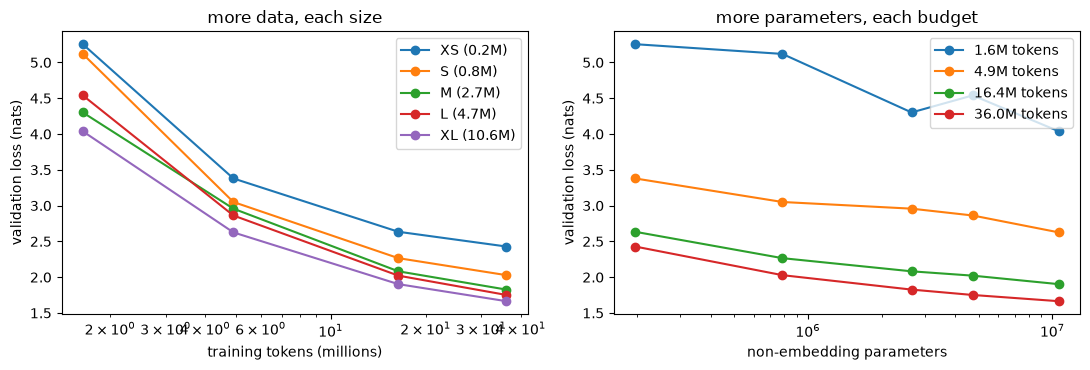

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for s in SIZES: axes[0].plot([st * BATCH * CTX / 1e6 for st in BUDGETS], [runs[f"grid/{s}/{st}/{best_lr[s]}"]["val_loss"] for st in BUDGETS], "o-", label=f"{s} ({n_ne[s] / 1e6:.1f}M)")
axes[0].set(xscale="log", xlabel="training tokens (millions)", ylabel="validation loss (nats)", title="more data, each size"); axes[0].legend()
for st in BUDGETS: axes[1].plot([n_ne[s] for s in SIZES], [runs[f"grid/{s}/{st}/{best_lr[s]}"]["val_loss"] for s in SIZES], "o-", label=f"{st * BATCH * CTX / 1e6:.1f}M tokens")
axes[1].set(xscale="log", xlabel="non-embedding parameters", ylabel="validation loss (nats)", title="more parameters, each budget"); axes[1].legend(); plt.tight_layout(); plt.show()

## 2. A fitted law

A scaling law gives the loss as a function of $N$ and $D$. We use the form in which each of the two terms is a power that falls to a floor:

$$
L(N,D)=E+\frac{A}{N^{\alpha}}+\frac{B}{D^{\beta}} .
$$

$E$ is the loss a model of unlimited size trained on unlimited data would reach on this text. The two other terms are what is lost to having too few parameters and too few tokens. We fit the five numbers $E,A,\alpha,B,\beta$ to the 15 runs of 300, 1,000 and 2,200 steps, with a least-squares fit.

In [7]:
FIT_BUDGETS = [300, 1000, 2200]                  # the 100-step runs are left out: they end before warm-up and start-up transients have faded
N = np.array([n_ne[s] for s in SIZES for st in FIT_BUDGETS], float); D = np.array([st * BATCH * CTX for s in SIZES for st in FIT_BUDGETS], float)
Lv = np.array([runs[f"grid/{s}/{st}/{best_lr[s]}"]["val_loss"] for s in SIZES for st in FIT_BUDGETS])
def law(X, E, A, a, B, b): return E + A * (X[0] / 1e6) ** -a + B * (X[1] / 1e6) ** -b
popt, _ = curve_fit(law, (N, D), Lv, p0=[1.2, 1.0, 0.3, 1.0, 0.3], maxfev=50000, bounds=([0, 0, 0, 0, 0], [5, 50, 2, 50, 2]))
E_, A_, a_, B_, b_ = popt; pred = law((N, D), *popt)
print(f"L(N, D) = {E_:.2f} + {A_:.2f} * N^-{a_:.2f} + {B_:.2f} * D^-{b_:.2f}   (N, D in millions)")
print(f"fitted to {len(Lv)} runs; largest error {np.abs(pred - Lv).max():.3f}, mean error {np.abs(pred - Lv).mean():.3f} nats")
short = np.array([law((n_ne[s], 100 * BATCH * CTX), *popt) - runs[f"grid/{s}/100/{best_lr[s]}"]["val_loss"] for s in SIZES]); print("fit minus measured loss for the five 100-step runs (not in the fit):", short.round(2))
N20 = np.array([n_ne[s] for s in SIZES for st in BUDGETS], float); D20 = np.array([st * BATCH * CTX for s in SIZES for st in BUDGETS], float); L20 = np.array([runs[f"grid/{s}/{st}/{best_lr[s]}"]["val_loss"] for s in SIZES for st in BUDGETS])
p20, _ = curve_fit(law, (N20, D20), L20, p0=[1.2, 1.0, 0.3, 1.0, 0.3], maxfev=50000, bounds=([0, 0, 0, 0, 0], [5, 50, 2, 50, 2]))
print(f"for comparison, fitting all 20 runs gives E = {p20[0]:.2f}, alpha = {p20[2]:.2f}, beta = {p20[4]:.2f} and a largest error of {np.abs(law((N20, D20), *p20) - L20).max():.2f} nats")

L(N, D) = 0.88 + 0.82 * N^-0.23 + 4.41 * D^-0.75   (N, D in millions)
fitted to 15 runs; largest error 0.080, mean error 0.031 nats
fit minus measured loss for the five 100-step runs (not in the fit): [-0.13 -0.32  0.28 -0.03  0.37]
for comparison, fitting all 20 runs gives E = 0.00, alpha = 0.13, beta = 0.74 and a largest error of 0.31 nats


The fit is $L = 0.88 + 0.82\,N^{-0.23} + 4.41\,D^{-0.75}$, with $N$ and $D$ in millions. It reproduces the 15 runs to a mean error of 0.031 nats and a largest error of 0.080. The five 100-step runs, which were left out, are off by $-0.32$ to $+0.37$ nats, so the law describes training that has got going and does not describe the first few hundred steps.

Read the numbers one at a time. The floor of 0.88 nats is a fitted number, extrapolated beyond all our data. The exponent on tokens (0.75) is more than three times the exponent on parameters (0.23), so in this range, adding data helps the loss much faster than adding parameters. That depends on how small our models are, and the exponents published for large models are different (Going deeper). The method carries over and the values do not.

With the law we can ask how to spend a fixed compute $C=6ND$. For each of three budgets, the figure plots the predicted loss against the model size when the rest of the compute goes into tokens. The best split is marked.

> **Pause:** for a fixed compute budget, is the loss lowest for the smallest model, the largest, or something in between?

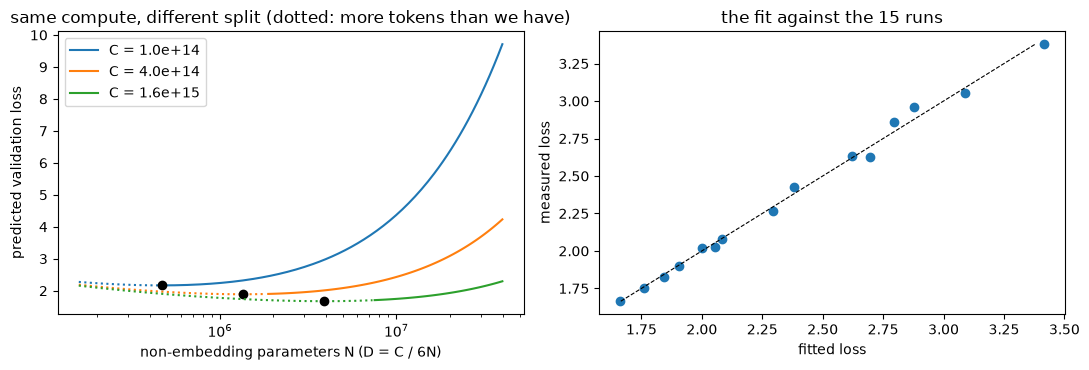

,compute C = 6ND (FLOPs),best N,tokens D,loss,within our 37M tokens,tokens_per_parameter
0,1.000000e+14,468114.14,35603852.31,2.17,True,76.06
1,4.000000e+14,1344755.15,49575319.85,1.89,False,36.87
2,1.600000e+15,3863088.64,69029393.70,1.67,False,17.87


In [8]:
C_levels = [1e14, 4e14, 1.6e15]; D_MAX = 2200 * BATCH * CTX
Ngrid = np.logspace(5.2, 7.6, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8)); opt = []
for C, colour in zip(C_levels, ("C0", "C1", "C2")):
    Dg = C / (6 * Ngrid); Lg = law((Ngrid, Dg), *popt); i = Lg.argmin(); opt.append((C, Ngrid[i], Dg[i], Lg[i], bool(Dg[i] <= D_MAX)))
    inside = Dg <= D_MAX; axes[0].plot(Ngrid[inside], Lg[inside], colour, label=f"C = {C:.1e}"); axes[0].plot(Ngrid[~inside], Lg[~inside], colour, ls=":"); axes[0].plot(Ngrid[i], Lg[i], "ko")
axes[0].set(xscale="log", xlabel="non-embedding parameters N (D = C / 6N)", ylabel="predicted validation loss", title="same compute, different split (dotted: more tokens than we have)"); axes[0].legend()
axes[1].scatter(pred, Lv); axes[1].plot([Lv.min(), Lv.max()], [Lv.min(), Lv.max()], "k--", lw=0.8); axes[1].set(xlabel="fitted loss", ylabel="measured loss", title=f"the fit against the {len(Lv)} runs"); plt.tight_layout(); plt.show()
display(pd.DataFrame(opt, columns=["compute C = 6ND (FLOPs)", "best N", "tokens D", "loss", "within our 37M tokens"]).assign(tokens_per_parameter=lambda t: t["tokens D"] / t["best N"]).round(2))

In between, with a broad minimum. The best model size for $C=10^{14}$ is 0.47M parameters trained on 35.6 million tokens, which is inside our data. For $4\times10^{14}$ it is 1.34M parameters with 49.6 million tokens (37 tokens per parameter), and for $1.6\times10^{15}$ it is 3.86M with 69.0 million tokens (18 tokens per parameter). The last two need more tokens than our 37 million, so they are extrapolations and are drawn dotted. Near each minimum the curve is flat: a model twice or half the best size loses very little, and the loss rises steeply only for much larger models, which would see too few tokens.

The right panel compares the fit with the measured losses.

## 3. Training small models for longer

The best split minimises the loss for a given training cost, and ignores the cost of using the model afterwards. A model is trained once and used many times, and the cost of every use grows with $N$. So a smaller model that is trained longer than the training-compute optimum, to the same loss, can be the better choice. We can ask the law how many tokens each size needs to reach a validation loss of 1.9.

In [9]:
target = 1.9; rows = []
for N_ in [1e6, 2e6, 4e6, 8e6, 16e6]:
    rest = (target - E_ - A_ * (N_ / 1e6) ** -a_) / B_
    if rest > 0: D_ = 1e6 * rest ** (-1 / b_); rows.append({"N (M)": N_ / 1e6, "tokens needed (M)": D_ / 1e6, "training compute 6ND (1e14 FLOPs)": 6 * N_ * D_ / 1e14, "tokens per parameter": D_ / N_, "within our 37M tokens": D_ <= D_MAX})
    else: rows.append({"N (M)": N_ / 1e6, "tokens needed (M)": np.inf, "training compute 6ND (1e14 FLOPs)": np.inf, "tokens per parameter": np.inf, "within our 37M tokens": False})
display(pd.DataFrame(rows).round(2))

,N (M),tokens needed (M),training compute 6ND (1e14 FLOPs),tokens per parameter,within our 37M tokens
0,1.0,65.22,3.91,65.22,False
1,2.0,33.95,4.07,16.98,True
2,4.0,23.21,5.57,5.80,True
3,8.0,17.96,8.62,2.25,True
4,16.0,14.93,14.33,0.93,True


To reach 1.9, a 1M-parameter model needs 65 million tokens, a 2M model 34 million, a 4M model 23 million, an 8M model 18 million and a 16M model 15 million. The training compute is $3.9\times10^{14}$, $4.1\times10^{14}$, $5.6\times10^{14}$, $8.6\times10^{14}$ and $14.3\times10^{14}$ FLOPs. So the smaller models cost less to train, and also less to run for every answer, but they need more text. The 1M model needs 65 million tokens, more than the 37 million we have, so that row is not available to us. The table is a prediction from the fit and not a measurement.

Current large models follow this logic. For example, the Llama 3 report (2024) trained an 8-billion-parameter model on about 15 trillion tokens, roughly 1,900 tokens per parameter, far past the compute-optimal ratio, because the model is used by many people.

## 4. Data

Everything so far used each token once. Real corpora are finite, so the next question is what happens when the data repeats. We train the largest model for 1,000 steps (16.4 million tokens) in three ways: on 16.4 million different tokens, on 4.1 million tokens seen 4 times, and on 1.0 million tokens seen 16 times.

> **Pause:** which of the three has the lowest validation loss, and which has the lowest training loss?

In [10]:
big = lambda tokens, key: run("XL", 1000, best_lr["XL"], key, data=train_ids[:tokens])
unique, repeated4, repeated16 = runs[f"grid/XL/1000/{best_lr['XL']}"], big(4_100_000, "repeat/4"), big(1_025_000, "repeat/16")
display(pd.DataFrame({"unique tokens": [16.4, 4.1, 1.0], "passes over them": [1, 4, 16], "training loss": [unique["train_loss"], repeated4["train_loss"], repeated16["train_loss"]], "validation loss": [unique["val_loss"], repeated4["val_loss"], repeated16["val_loss"]]}, index=["all new", "repeated 4 times", "repeated 16 times"]).round(3))

,unique tokens,passes over them,training loss,validation loss
all new,16.4,1,1.999,1.903
repeated 4 times,4.1,4,1.878,1.964
repeated 16 times,1.0,16,1.057,2.692


New data gives a validation loss of 1.903. Four passes over a quarter of the data give 1.964, a small loss of 0.06 nats. Sixteen passes over a sixteenth of the data give 2.692, with a training loss of 1.057: the model has memorised its 1.0 million tokens and predicts held-out text much worse. Repeating text a few times costs little, and repeating it many times does harm.

A related problem is duplication inside the data: near-copies of the same document, which a model can memorise. Exact duplicates are easy to remove. Near-duplicates need a similarity measure. We split each story into overlapping 5-word shingles and use the Jaccard similarity of the two shingle sets, which is 1 for identical stories and 0 for stories that share nothing. Comparing all pairs of 20,000 stories is too slow, so we use MinHash: a 64-number signature per story such that two stories with similar shingle sets have matching numbers, and compare only stories that match in some band of the signature.

To test the method we need examples where we know the answer. We copy 200 stories at each of four edit levels, replace 2%, 5%, 10% or 20% of the words with random words, add the copies to the corpus, and see how many are found.

In [11]:
import glob, zlib
P = 2**31 - 1
def shingles(text, k=5):
    w = text.lower().split(); return np.array(sorted({zlib.crc32(" ".join(w[i:i + k]).encode()) % P for i in range(len(w) - k + 1)}), dtype=np.uint64)
stories = pd.read_parquet(glob.glob(os.path.expanduser("~/.cache/huggingface/hub/datasets--roneneldan--TinyStories/snapshots/*/data/train-00000*.parquet"))[0]).text.tolist()[:20000]
rng = np.random.default_rng(0); vocab_words = sorted({w for s in stories[:500] for w in s.split()})
def edit(text, rate):
    """A copy of the text in which a fraction `rate` of the words is replaced by random words."""
    return " ".join(rng.choice(vocab_words) if rng.random() < rate else w for w in text.split())
planted = {rate: [(i, edit(stories[i], rate)) for i in rng.choice(len(stories), 200, replace=False)] for rate in (0.02, 0.05, 0.10, 0.20)}
corpus = stories + [t for rate in planted for _, t in planted[rate]]
sh = [shingles(s) for s in corpus]
A_h, B_h = rng.integers(1, P, (2, 64), dtype=np.uint64)
sig = np.array([((A_h[:, None] * h[None, :] + B_h[:, None]) % P).min(1) if len(h) else np.zeros(64, dtype=np.uint64) for h in sh])     # MinHash signature: 64 numbers per story
buckets = {}
for i, row in enumerate(sig):
    for band in range(16): buckets.setdefault((band, tuple(row[band * 4:(band + 1) * 4])), []).append(i)                    # stories that share a band of the signature are candidates
pairs = {(a, b) for ids_ in buckets.values() if 1 < len(ids_) < 50 for a in ids_ for b in ids_ if a < b}
jac = lambda a, b: len(np.intersect1d(sh[a], sh[b])) / max(1, len(np.union1d(sh[a], sh[b])))
found = {p: jac(*p) for p in pairs}
rows = []; offset = len(stories)
for rate in planted:
    truth = [(i, offset + j) for j, (i, _) in enumerate(planted[rate])]; offset += len(truth)
    rows.append({"words replaced": f"{rate:.0%}", "planted copies": len(truth), "true Jaccard (mean)": np.mean([jac(a, b) for a, b in truth]), "found as candidates": sum(tuple(sorted(t)) in pairs for t in truth) / len(truth), "found with Jaccard >= 0.5": sum(found.get(tuple(sorted(t)), 0) >= 0.5 for t in truth) / len(truth)})
display(pd.DataFrame(rows).round(2))
natural = sorted([(v, a, b) for (a, b), v in found.items() if a < len(stories) and b < len(stories) and v >= 0.5], reverse=True)
print(f"{len(stories):,} original stories: {len(natural)} pairs with Jaccard >= 0.5 among them")

,words replaced,planted copies,true Jaccard (mean),found as candidates,found with Jaccard >= 0.5
0,2%,200,0.83,1.00,1.00
1,5%,200,0.65,0.88,0.86
2,10%,200,0.41,0.40,0.12
3,20%,200,0.21,0.05,0.00


20,000 original stories: 0 pairs with Jaccard >= 0.5 among them


Copies with 2% of their words replaced have a Jaccard similarity of 0.83 on average, and all 200 are found. With 5% replaced the similarity is 0.65, and 86% are found with a similarity of at least 0.5. With 10% replaced it is 0.41, and only 12% of copies reach 0.5 (40% are even candidates). With 20% replaced it is 0.21, and 0% are found. So "near-duplicate" is defined by the shingle length and the threshold, and a copy with a tenth of its words changed is already below 0.5.

Among the 20,000 original stories there are no pairs with a similarity of 0.5 or more. TinyStories was generated, not scraped, and that is a different situation from a web crawl, where large amounts of near-duplicate text are expected.

## 5. Smooth and thresholded metrics

Scaling studies often report a task score and not a loss, and a score can look different from the loss. As a small case, we use the final models of all five sizes, take 1,500 held-out 64-token contexts, and measure two things: how often the model's top guess for the next token is right, and how often it gets all of the next five tokens right when it writes them itself.

,next-token accuracy,all 5 tokens right,accuracy ** 5
XS,0.454,0.027,0.019
S,0.528,0.051,0.041
M,0.557,0.057,0.054
L,0.575,0.074,0.063
XL,0.591,0.086,0.072


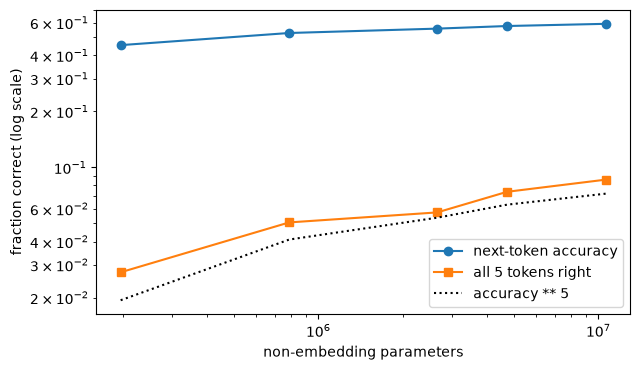

In [12]:
@torch.no_grad()
def predict_next(size, n=1500, k=5, ctx=64):
    m = make(size).to(DEVICE); m.load_state_dict(torch.load(f"cache/final_{size}.pt")); m.eval()
    x, y = window_batch(val_ids, torch.randint(0, len(val_ids) - ctx - k - 1, (n,), generator=torch.Generator().manual_seed(7)), ctx + k - 1)
    truth = y[:, ctx - 1:]                                                                   # the next k real tokens after each 64-token context
    per_token = (m(x)[0][:, ctx - 1:].argmax(-1) == truth).float().mean().item()              # each predicted from the real text before it
    exact = (m.generate(x[:, :ctx], k, greedy=True)[:, ctx:] == truth).all(1).float().mean().item()   # all k right when the model writes them itself
    return per_token, exact
acc = pd.DataFrame({s: predict_next(s) for s in SIZES}, index=["next-token accuracy", "all 5 tokens right"]).T; acc["accuracy ** 5"] = acc["next-token accuracy"] ** 5
display(acc.round(3))
plt.figure(figsize=(6.5, 3.8)); xs = [n_ne[s] for s in SIZES]
for col, style in [("next-token accuracy", "o-"), ("all 5 tokens right", "s-"), ("accuracy ** 5", "k:")]: plt.plot(xs, acc[col], style, label=col)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("non-embedding parameters"); plt.ylabel("fraction correct (log scale)"); plt.legend(); plt.tight_layout(); plt.show()

The next-token accuracy rises smoothly with size, from 0.454 to 0.591, a factor of 1.3. The probability of getting all five tokens right rises from 0.027 to 0.086, a factor of 3.2, and it stays close to the fifth power of the single-token accuracy (0.019 to 0.072). Requiring five things in a row to be right turns a gentle improvement into a steep one. Nothing in these models changed abruptly. A benchmark that scores only whole answers as right or wrong can show a sudden jump with size where the underlying per-token ability improved smoothly, which is one explanation offered for apparently sudden new abilities. Our models are too small and too close in ability to show a jump, and the figure shows only the amplification.

## What to take away

- Compute for a dense model is about $6ND$. In our grid, the loss falls steadily with both parameters and tokens, and the best learning rate falls with size (0.012 for the 0.2M model, 0.003 for the 10.6M one).
- A five-parameter law fitted to 15 runs reproduces them to a mean error of 0.031 nats. It is least reliable at the edges: short runs (off by up to 0.37) and any prediction that needs more tokens than we trained on.
- For a fixed compute budget the loss has a broad minimum in model size. A smaller model trained on more tokens reaches the same loss at less cost to run, as long as there is enough text.
- Repeating 4.1 million tokens four times costs 0.06 nats against new data. Repeating 1.0 million tokens 16 times gives a training loss of 1.06 and a validation loss of 2.69.
- MinHash finds copies with 2% of the words changed in every case, and 12% of copies with 10% changed, so the similarity threshold defines what is removed.
- A metric that needs several things right at once amplifies a smooth change: 1.3 times in per-token accuracy became 3.2 times in five-token accuracy.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## Published scaling laws

Kaplan et al. (2020), *Scaling Laws for Neural Language Models*, found that the loss of transformer language models falls as a power law in parameters, data and compute over many orders of magnitude, and concluded that for a fixed budget it is best to grow the model faster than the data. Hoffmann et al. (2022), *Training Compute-Optimal Large Language Models*, repeated the study with a more careful treatment of the learning-rate schedule and fitted the same form we used. They reported exponents of about 0.34 for parameters and 0.28 for tokens, and concluded that parameters and tokens should grow together, at roughly 20 tokens per parameter. A model of 70 billion parameters trained on 1.4 trillion tokens (Chinchilla) matched a much larger model trained on fewer tokens.

Our exponents (0.23 and 0.75) and our trend of tokens per parameter falling with compute differ from those. We have models of 0.2M to 10.6M parameters and at most 36 million tokens, one pass over one narrow dataset, and a floor $E$ that the fit puts at 0.88. Different ranges give different local exponents. The point of the exercise is the procedure: tune the learning rate per size, run a grid, fit, and test the fit where you can.

## Why 6ND

A matrix multiplication of an $n\times d$ input with a $d\times m$ weight takes $2ndm$ operations. Over all the weights in the blocks, a forward pass over $D$ tokens takes about $2ND$. The backward pass computes gradients with respect to both the activations and the weights, about twice the cost of the forward pass, which makes $4ND$. Attention scores, which grow with context length, are not counted, and neither are the embedding table and the output layer. For models with long contexts the correction is not small.

## Total and active parameters

In a mixture-of-experts layer, each token is sent to a few of many expert MLPs. The model has many more parameters in total than it uses for any one token. The compute per token is $6N_{\text{active}}$, and the memory needed to hold the model is set by $N_{\text{total}}$. Scaling laws fitted to dense models do not transfer directly, since the loss depends on both.

## Fitting

The five-parameter fit can have several nearly equivalent solutions, especially with a small number of runs. We used bounds and a sensible starting point, and the fit hit no bound. The notebook prints the comparison: with the 100-step runs included the fit puts $E$ at its lower bound of 0 and its largest error is four times higher. A fit that depends on a few choices like these should be reported with them.

## Thresholded metrics

Schaeffer et al. (2023), *Are Emergent Abilities of Large Language Models a Mirage?*, argued that many reported jumps in ability come from the choice of metric, as in section 5. They do not say that abilities never change sharply, and our small test cannot say either.